# Lepton reconstruction efficiency vs $L_{xy}$

Measure the reconstruction efficiency of electrons, photons, PF muons, and DSA muons as a function of the gen-level dark photon $L_{xy}$.

The association between reco objects and gen dark photons is the same as in the `*_nearGenA_n_genA_lxy` hists used in `leptonReco.ipynb`: a reco object belongs to a gen dark photon if it lies within $\Delta R < 0.5$ of it. Electrons and photons are compared to $A \to ee$, PF and DSA muons to $A \to \mu\mu$. For each object type and each $L_{xy}$ bin:
- $\epsilon_{\geq 1}$ = fraction of dark photons with at least one associated reco object
- $\epsilon_{\geq 2}$ = fraction of dark photons with at least two associated reco objects (i.e. both leptons reconstructed)

The numerator and denominator hists are defined at the end of `sidm/definitions/hists.py` and grouped in the `lepton_recoEff_lxy` hist collection. Uncertainties are 68.3% Clopper-Pearson intervals.

In [1]:
# python
import os
import sys
import importlib
# columnar analysis
from coffea import processor
import awkward as ak
import hist
from dask.distributed import Client, performance_report
# numerics
import numpy as np
from scipy import stats
# local
sidm_path = str(os.getcwd()).split("/sidm")[0]
if sidm_path not in sys.path: sys.path.insert(1, sidm_path)
from sidm.tools import utilities, sidm_processor, scaleout, llpnanoaodschema
# always reload local modules to pick up changes during development
importlib.reload(utilities)
importlib.reload(sidm_processor)
importlib.reload(scaleout)
importlib.reload(llpnanoaodschema)
# plotting
import matplotlib.pyplot as plt
utilities.set_plot_style()
%matplotlib inline

In [2]:
client = scaleout.make_dask_client("tls://localhost:8786")
client

<Client: 'tls://192.168.235.40:8786' processes=2 threads=2, memory=7.64 GiB>

To cover a wide $L_{xy}$ range, run over every available lifetime of four (bound state mass, dark photon mass) points that more or less span the possible gen-lepton $\Delta R$ values, then sum the lifetime samples of each mass point. Hists are filled unweighted (raw counts), so the binomial uncertainty is exact. Run both without and with the LJ-source (object ID) cuts to see how much of the inefficiency comes from reconstruction itself vs. the object selection.

In [3]:
# all available lifetimes for each (bound state mass, dark photon mass) point
mass_points = {
    "100GeV_0p25GeV":  ["0p02mm", "0p2mm", "2p0mm", "10p0mm", "20p0mm"],
    "100GeV_5p0GeV":   ["0p4mm", "4p0mm", "40p0mm", "200mm", "400mm"],
    "1000GeV_0p25GeV": ["0p002mm", "0p02mm", "0p2mm", "1p0mm", "2p0mm"],
    "1000GeV_5p0GeV":  ["0p04mm", "0p4mm", "4p0mm", "20p0mm", "40p0mm"],
}
samples = {mp: [f"2Mu2E_{mp}_{ctau}" for ctau in ctaus] for mp, ctaus in mass_points.items()}
all_samples = [s for mp_samples in samples.values() for s in mp_samples]

print(all_samples[::7])

# all_samples = [all_samples[], ]

max_files = -1
fileset = utilities.make_fileset(all_samples, "llpNanoAOD_v2", max_files=max_files, location_cfg="signal_2mu2e_v10.yaml")

runner = processor.Runner(
    #executor=processor.IterativeExecutor(),
    executor=processor.DaskExecutor(client=client),
    schema=llpnanoaodschema.LLPNanoAODSchema,
    #maxchunks=1,
    skipbadfiles=True,
)

# without and with the LJ-source cuts
channels = ["baseNoLjNoLjsource", "baseNoLj"]
channels = ["base", "base_sr"]
p = sidm_processor.SidmProcessor(
    channels,
    ["lepton_recoEff_lxy"],
    unweighted_hist=True,  # raw counts -> exact binomial uncertainties
)

['2Mu2E_100GeV_0p25GeV_0p02mm', '2Mu2E_100GeV_5p0GeV_40p0mm', '2Mu2E_1000GeV_0p25GeV_2p0mm']


In [4]:
output = runner.run(fileset, treename="Events", processor_instance=p)
out = output["out"]

Output()

Output()

2Mu2E_1000GeV_5p0GeV_40p0mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_1000GeV_5p0GeV_20p0mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_100GeV_5p0GeV_200mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_100GeV_0p25GeV_0p02mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_100GeV_0p25GeV_0p2mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_100GeV_0p25GeV_2p0mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_100GeV_0p25GeV_10p0mm is simulation. Scaling histograms or cutflows according to lumi*xs.
Ignoring signal cross sections, assuming 1 fb
2Mu2E_100G

In [ ]:
#Or, load already procecssed data
import coffea.util
output = coffea.util.load('output_leptonRecoEff_vs_lxy.coffea')
out = output["out"]

Helper functions to sum hists over samples, compute the efficiency with a Clopper-Pearson interval, and plot the efficiency of all four object types vs $L_{xy}$.

In [5]:
# reco object -> (plot label, denominator hist); the denominator is the gen dark photon decay flavor
reco_objs = {
    "electron": ("Electron", "genAs_toE_lxy_recoEff"),
    "photon":   ("Photon",   "genAs_toE_lxy_recoEff"),
    "muon":     ("PF muon",  "genAs_toMu_lxy_recoEff"),
    "dsaMuon":  ("DSA muon", "genAs_toMu_lxy_recoEff"),
}


def sum_samples(proc_output, sample_list, hist_name, channel):
    # sum one channel of a hist over several samples (e.g. all lifetimes of one mass point)
    return sum(proc_output[s]["hists"][hist_name][channel, :] for s in sample_list)


def clopper_pearson(k, n, cl=0.682689):
    # Clopper-Pearson interval for k passing out of n trials (k, n may be non-integer effective counts)
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    alpha = 1 - cl
    with np.errstate(divide="ignore", invalid="ignore"):
        lo = np.where(k > 0, stats.beta.ppf(alpha/2, k, n - k + 1), 0.0)
        hi = np.where(k < n, stats.beta.ppf(1 - alpha/2, k + 1, n - k), 1.0)
    return lo, hi


def efficiency(num, den, cl=0.682689):
    # Per-bin efficiency num/den and its asymmetric (down, up) errors; bins with an empty
    # denominator are nan. Effective counts sum(w)^2/sum(w^2) are used for the interval, which
    # equal the raw counts for unweighted hists and keep weighted hists usable as well.
    n, k, n_var = den.values(), num.values(), den.variances()
    with np.errstate(divide="ignore", invalid="ignore"):
        eff = np.where(n > 0, k/n, np.nan)
        n_eff = np.where(n_var > 0, n**2/n_var, 0.0)
    k_eff = np.clip(eff, 0, 1)*n_eff
    lo, hi = clopper_pearson(k_eff, n_eff, cl)
    return eff, eff - lo, hi - eff


def eff_hist(num, den):
    # Return an efficiency hist (variance = symmetrized error^2) and the asymmetric errors to plot
    eff, err_down, err_up = efficiency(num, den)
    h = hist.Hist(*den.axes, storage=hist.storage.Weight())
    h.view().value[:] = eff
    h.view().variance[:] = (0.5*(err_down + err_up))**2
    return h, np.array([err_down, err_up])

In [6]:
def plot_eff_vs_lxy(proc_output, sample_list, channel, title="", logx=True, suffix=""):
    # left: >=1 reco object near the dark photon, right: >=2 (both leptons); all object types overlaid
    fig, axes = plt.subplots(1, 2, figsize=(24, 10), sharey=True)
    for ax, min_n in zip(axes, [1, 2]):
        plt.sca(ax)
        for i, (obj, (label, den_name)) in enumerate(reco_objs.items()):
            num = sum_samples(proc_output, sample_list, f"{obj}_nearGenA_ge{min_n}_genA_lxy", channel)
            den = sum_samples(proc_output, sample_list, den_name, channel)
            h_eff, errors = eff_hist(num, den)
            utilities.plot(h_eff, histtype="errorbar", yerr=np.nan_to_num(errors), flow="none",
                           skip_label=(i > 0), label=label, markersize=12)
        if logx:
            edges = den.axes[0].edges
            ax.set_xscale("log")
            ax.set_xlim(0.3*edges[1], edges[-1])
        ax.set_ylim(0, 1.2)
        # efficiencies fall with Lxy, so the lower left is usually empty
        ax.legend(title=rf"$\geq${min_n} reco within $\Delta R<0.5$ of dark photon",
                  alignment="left", loc="lower left")
    axes[0].set_ylabel("Reconstruction efficiency")
    axes[1].set_ylabel(None)
    fig.suptitle(f"{title}, channel: {channel}", y=1.0)
    fig.subplots_adjust(wspace=0.05, top=0.88)
    #plt.savefig(f"{sidm_path}/plots/lepton_recoEff_vs_lxy_{channel}{suffix}.png", bbox_inches="tight")
    return fig


def mass_point_title(mass_point):
    bs_mass, dp_mass = mass_point.split("_")
    bs_mass = bs_mass.replace("GeV", " GeV")
    dp_mass = dp_mass.replace("p", ".").replace("GeV", " GeV")
    return f"Bound state mass = {bs_mass}, dark photon mass = {dp_mass}"

Efficiency vs $L_{xy}$ for each mass point (all lifetimes summed).

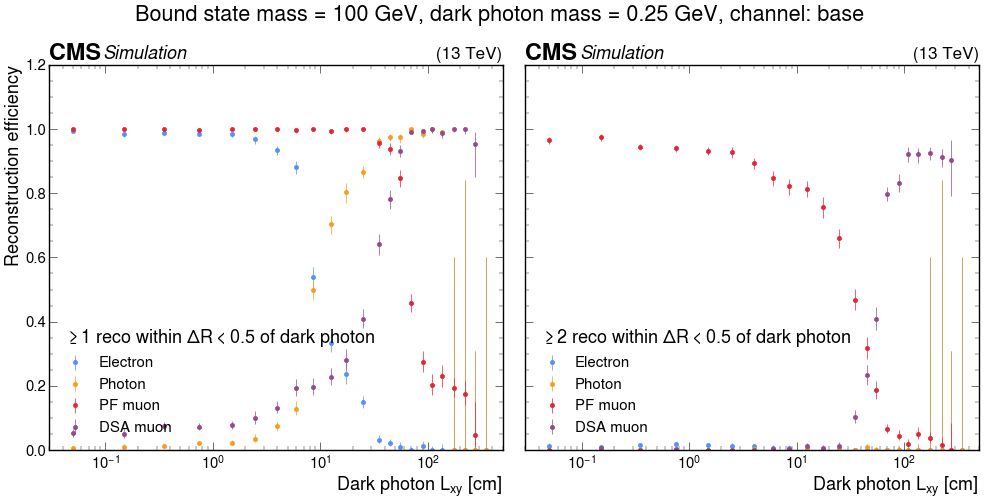

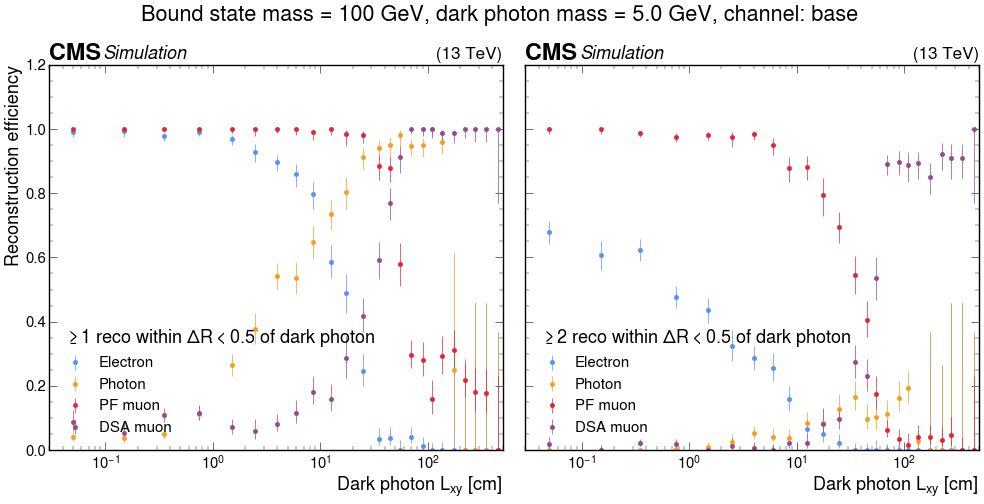

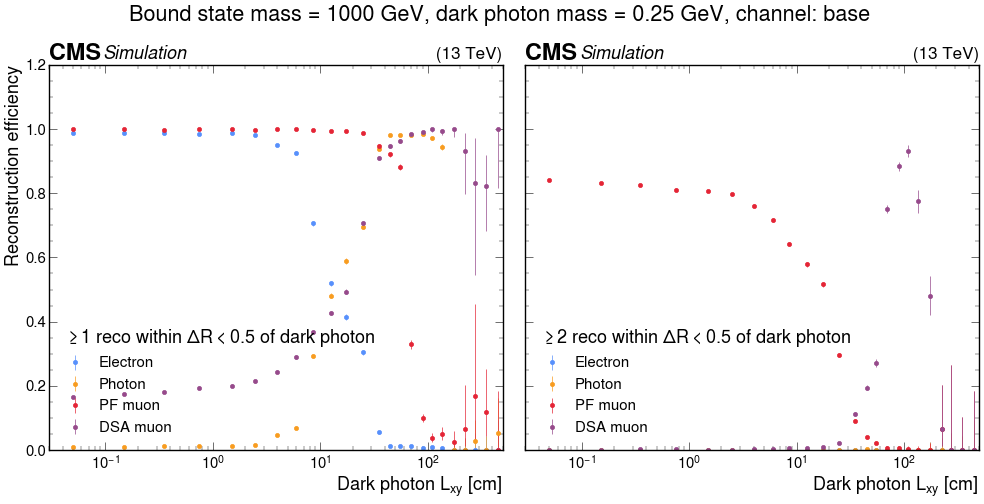

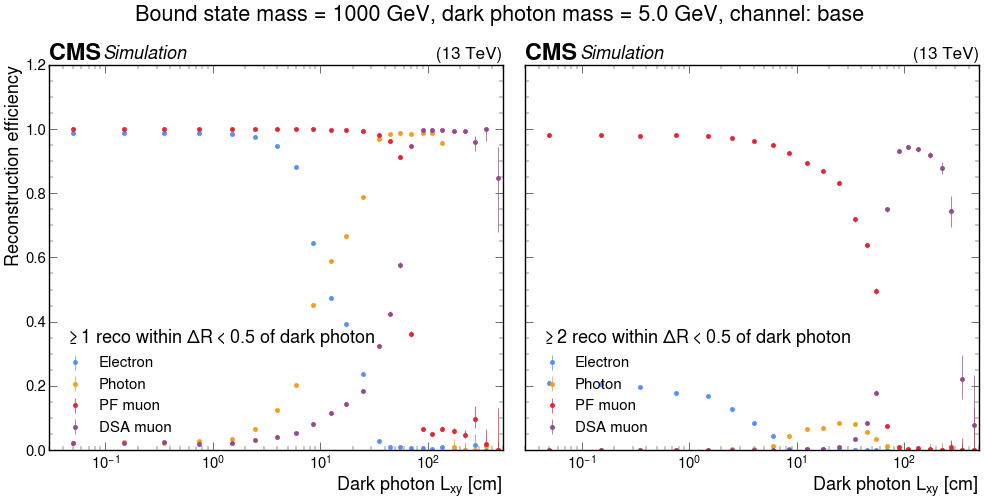

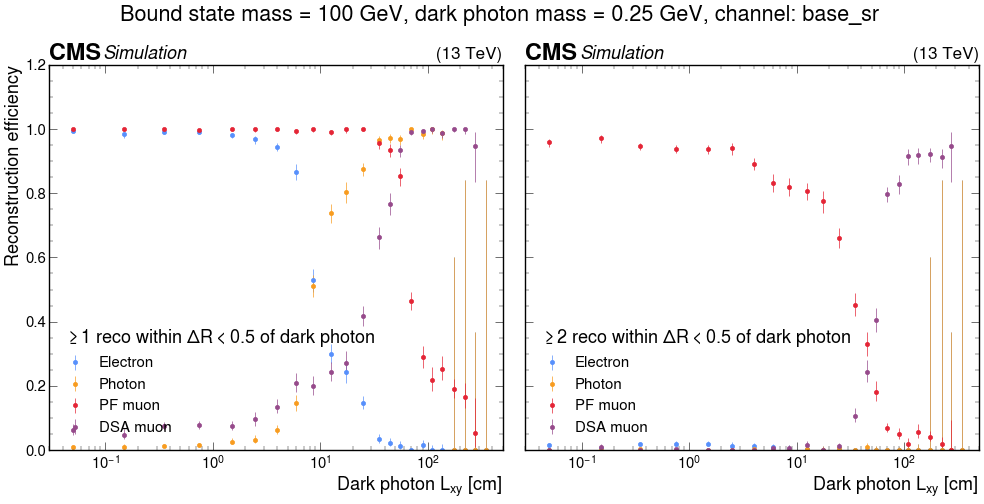

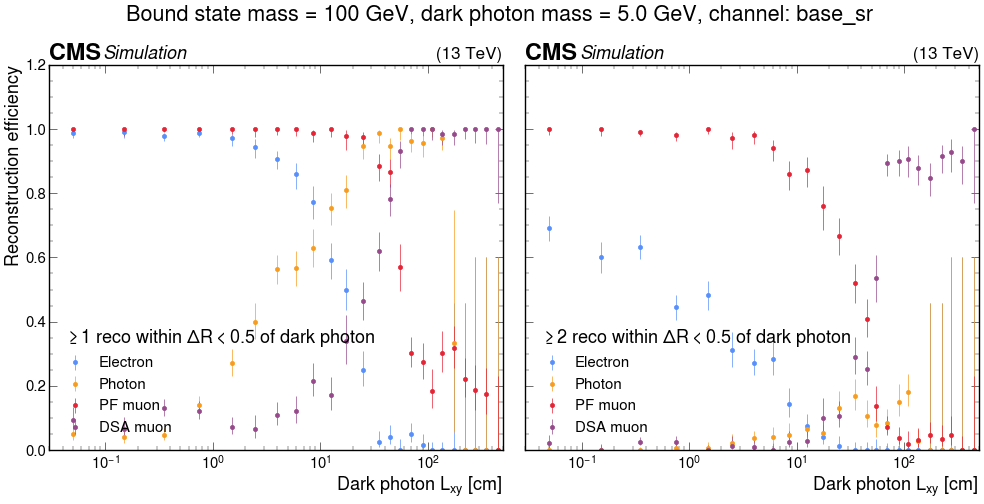

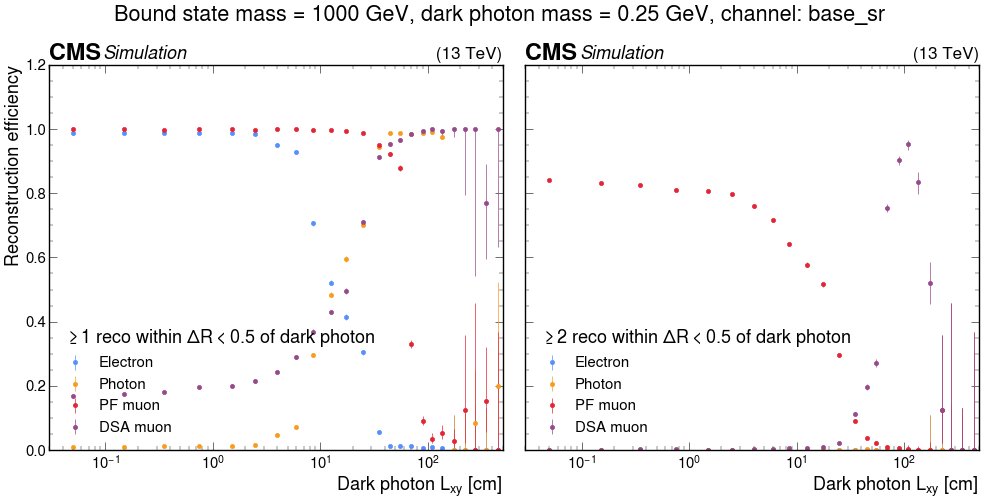

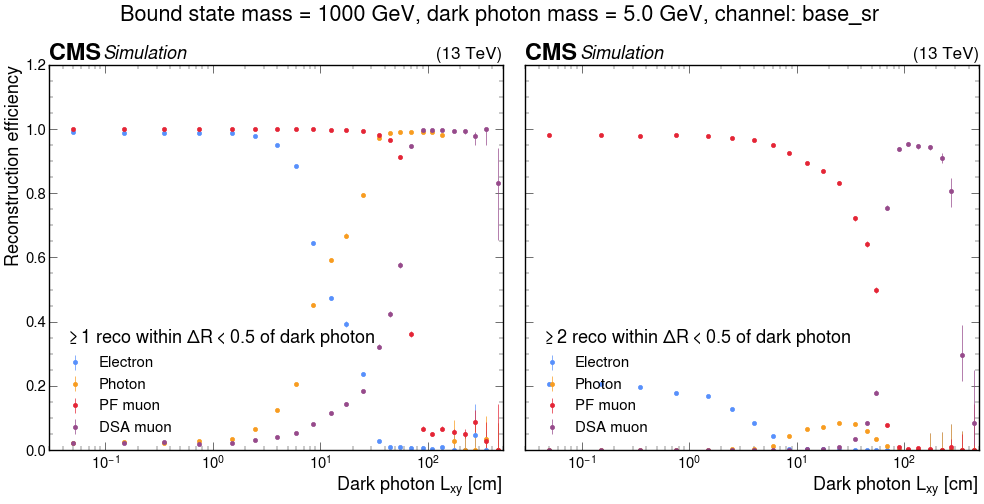

In [10]:
for channel in channels:
    for mass_point, sample_list in samples.items():
        plot_eff_vs_lxy(out, sample_list, channel, title=mass_point_title(mass_point), suffix=f"_{mass_point}", logx=True)

All mass points combined. Note that the relative contribution of each mass point (and hence the gen-lepton $\Delta R$ distribution) varies with $L_{xy}$, so this is mostly useful as an overview.

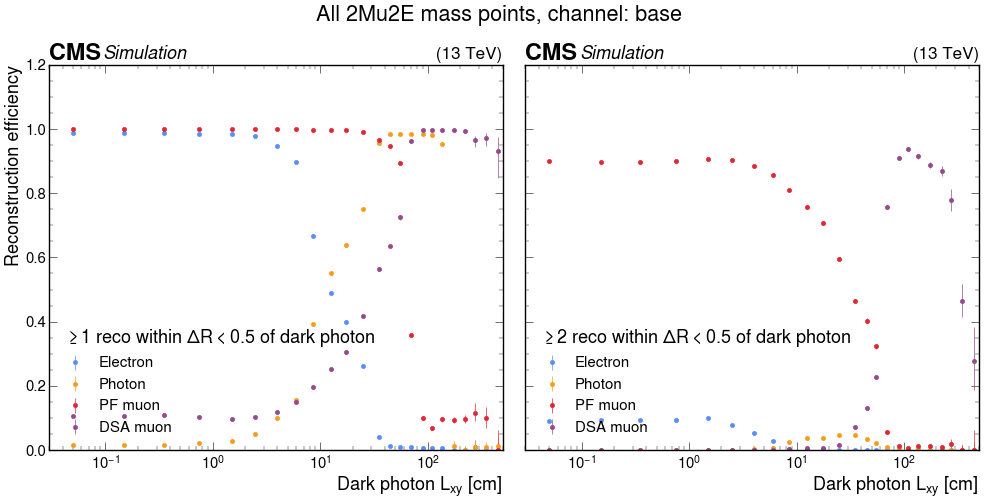

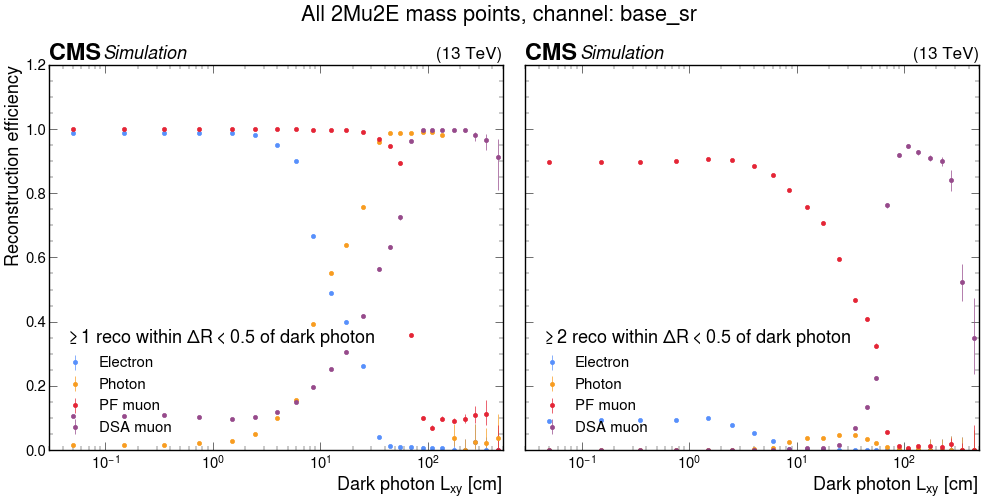

In [8]:
for channel in channels:
    plot_eff_vs_lxy(out, all_samples, channel, title="All 2Mu2E mass points", suffix="_allMassPoints")

In [9]:
# save output
import coffea.util
coffea.util.save(output, "output_leptonRecoEff_vs_lxy.coffea")